# Phase 1 – Ground Truth (Mais)

Überblick über die aufbereiteten Referenzdaten: Umfang, Ertragsverteilung, Harmonisierungsprüfung HLS vs. Sentinel-2,
Sichtprüfung der Kurvenform, Beobachtungsdichte und erste Indikator-Ertrags-Korrelationen.
Es werden ausschließlich bereits verarbeitete Dateien gelesen (keine österreichischen Daten).

In [1]:
import glob
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve repo root whether run from notebooks/ or the root
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
RES = sorted(glob.glob(str(ROOT / "results" / "*_phase1")))[-1]
print("Ergebnisordner:", Path(RES).name)

fy = pd.read_parquet(PROC / "gt_field_years.parquet").drop(columns="geometry")
exc = pd.read_csv(PROC / "gt_excluded.csv")
dek = pd.read_parquet(PROC / "gt_dekads.parquet")
harm = json.loads((PROC / "harmonisation_check.json").read_text())
ind = pd.read_csv(Path(RES) / "indicators_vs_yield.csv")
pd.options.display.float_format = "{:.3f}".format

Ergebnisordner: 2026-10-16_phase1


## 1. Umfang der Mais-Feld-Jahre

In [2]:
cnt = (fy.groupby(["dataset", "sensor_era"])
         .agg(feld_jahre=("fy_key", "size"), felder=("field_uid", "nunique"),
              jahre=("year", "nunique"), mit_RY=("RY_descr", "count"))
         .reset_index())
tot = pd.DataFrame([{"dataset": "Summe", "sensor_era": "",
                     "feld_jahre": len(fy), "felder": fy.field_uid.nunique(),
                     "jahre": fy.groupby("dataset").year.nunique().sum(),
                     "mit_RY": fy.RY_descr.notna().sum()}])
display(pd.concat([cnt, tot], ignore_index=True))
print("Anmerkung: 'jahre' in der Summenzeile = Summe der Jahre je Datensatz (Standort-Jahre).")

,dataset,sensor_era,feld_jahre,felder,jahre,mit_RY
0,BARC,HLS,61,33,7,27
1,Colorado,HLS,10,10,4,0
2,KBS,HLS,96,24,4,96
3,KBS,L57,198,24,10,198
4,Summe,,365,67,25,321


Anmerkung: 'jahre' in der Summenzeile = Summe der Jahre je Datensatz (Standort-Jahre).


**Ausgeschlossene Zeilen** (aus `gt_excluded.csv`) mit Grund:

In [3]:
display(exc.groupby(["dataset", "reason"]).agg(anzahl=("year", "size"),
        jahre=("year", lambda s: ", ".join(map(str, sorted(s.unique()))))).reset_index())

,dataset,reason,anzahl,jahre
0,BARC,"raster unit unclear (mean 3.31, expected bu/ac)",1,2017
1,KBS,no whole_plot yield,5,"1991, 1996"
2,KBS,unexplained treatment label (not T1-T4),1,1999


## 2. Ertrag und relativer Ertrag (RY_descr)
`RY_descr` ist der beschreibende relative Ertrag je Datensatz-Jahr (nur dort vorhanden, wo eine Referenz existiert).
Der Anteil RY < 0,85 dient als grobe Messgröße für Stressjahre/-felder.

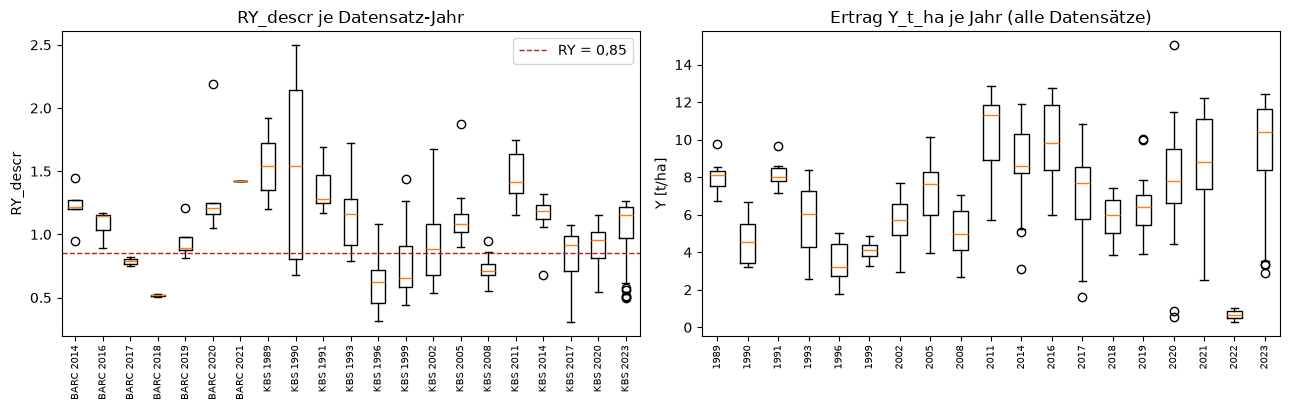

In [4]:
fy["ds_year"] = fy.dataset + " " + fy.year.astype(str)
r = fy.dropna(subset=["RY_descr"])
order = sorted(r.ds_year.unique())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].boxplot([r.loc[r.ds_year == k, "RY_descr"] for k in order], tick_labels=order, showfliers=True)
ax[0].axhline(0.85, color="firebrick", ls="--", lw=1, label="RY = 0,85")
ax[0].set(ylabel="RY_descr", title="RY_descr je Datensatz-Jahr"); ax[0].legend()
ax[0].tick_params(axis="x", rotation=90, labelsize=7)
yy = sorted(fy.year.unique())
ax[1].boxplot([fy.loc[fy.year == y, "Y_t_ha"].dropna() for y in yy], tick_labels=yy)
ax[1].set(ylabel="Y [t/ha]", title="Ertrag Y_t_ha je Jahr (alle Datensätze)")
ax[1].tick_params(axis="x", rotation=90, labelsize=7)
fig.tight_layout(); plt.show()

In [5]:
low = (r.assign(low=r.RY_descr < 0.85).groupby("ds_year")
        .agg(n=("low", "size"), anteil_RY_unter_085=("low", "mean")).reset_index())
display(low)
print(f"Gesamt: {(r.RY_descr < 0.85).mean():.1%} der {len(r)} Feld-Jahre mit RY haben RY < 0,85.")

,ds_year,n,anteil_RY_unter_085
0,BARC 2014,5,0.000
1,BARC 2016,5,0.000
2,BARC 2017,4,1.000
3,BARC 2018,2,1.000
4,BARC 2019,5,0.200
5,BARC 2020,5,0.000
6,BARC 2021,1,0.000
7,KBS 1989,12,0.000
8,KBS 1990,12,0.333
9,KBS 1991,8,0.000


Gesamt: 34.0% der 321 Feld-Jahre mit RY haben RY < 0,85.


## 3. Harmonisierungsprüfung (HLS vs. Sentinel-2, Dekadenmittel)
Kriterien: |Bias (Median-Differenz)| ≤ 0,03 und RMSD ≤ 0,07.

In [6]:
crit = harm["criteria"]
h = pd.DataFrame(harm["results"]).T.rename_axis("index").reset_index()
h[["n_pairs", "n_field_years"]] = h[["n_pairs", "n_field_years"]].astype(int)
h["bias_ok"] = h.median_diff.abs() <= crit["bias_max"]
h["rmsd_ok"] = h.rmsd <= crit["rmsd_max"]
display(h)
print("Gesamtergebnis:", "bestanden" if harm["passed"] else "NICHT bestanden",
      f"(Grenzen: |Bias| <= {crit['bias_max']}, RMSD <= {crit['rmsd_max']})")

,index,n_pairs,n_field_years,median_diff,rmsd,spearman,bias_ok,rmsd_ok
0,ndvi,413,133,-0.016,0.073,0.937,True,False
1,evi,413,133,-0.021,0.080,0.933,True,False


Gesamtergebnis: NICHT bestanden (Grenzen: |Bias| <= 0.03, RMSD <= 0.07)


## 4. Sichtprüfung der Kurvenform
24 zufällige HLS-Feld-Jahre (Seed 42), NDVI auf HLS-Basis. Punkte = beobachtete Dekaden, Linie = interpolierte Kurve.

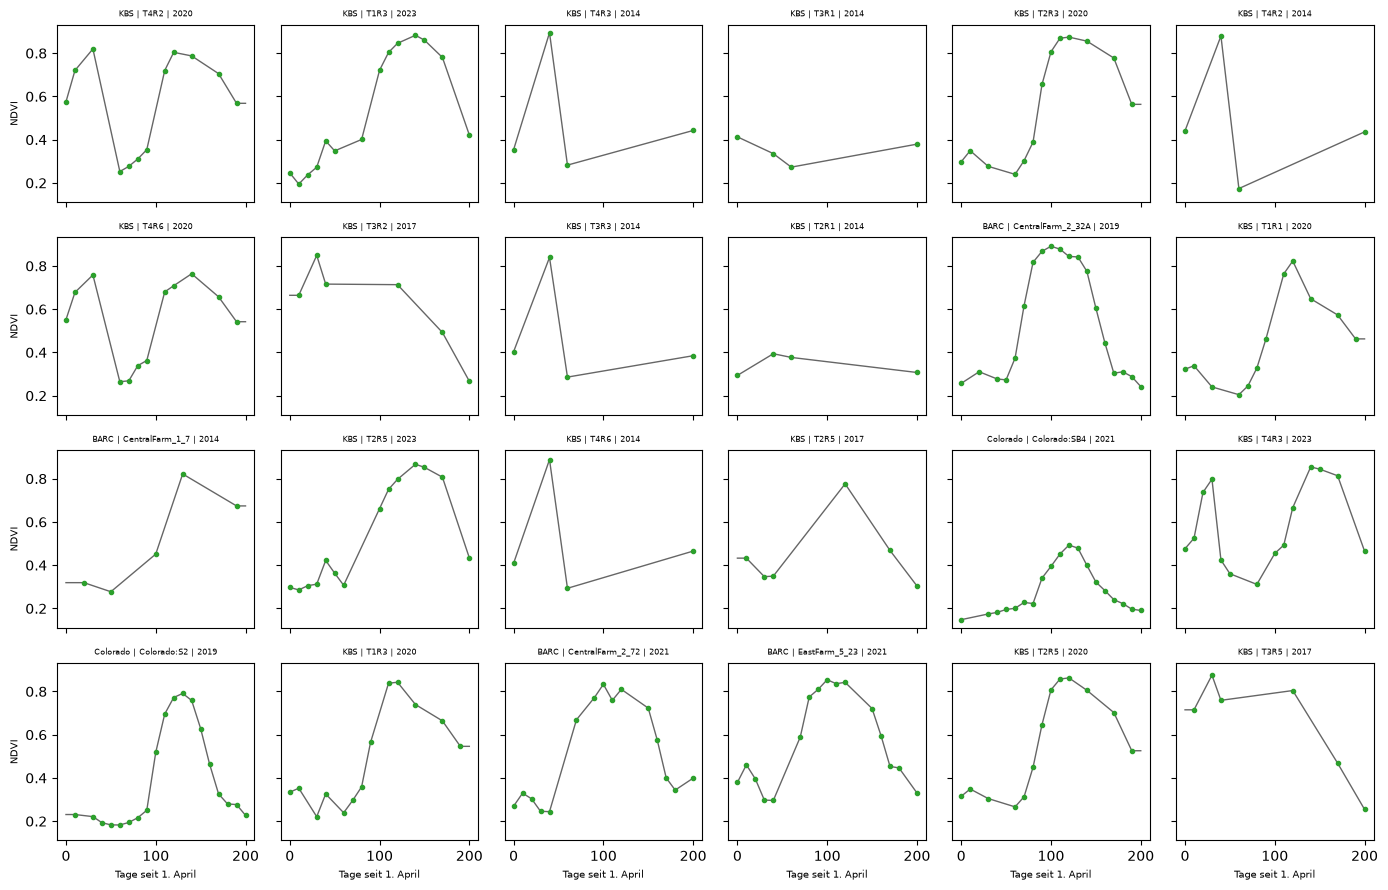

phase1_curve_sample.png 115 KB


In [7]:
rng = np.random.default_rng(42)
hls_keys = np.sort(fy.loc[fy.sensor_era == "HLS", "fy_key"].unique())
pick = rng.choice(hls_keys, 24, replace=False)
sub = dek[(dek.basis == "HLS") & (dek["index"] == "ndvi") & dek.fy_key.isin(pick)]
fig, axes = plt.subplots(4, 6, figsize=(14, 9), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), pick):
    d = sub[sub.fy_key == k].sort_values("dekad")
    x = d.dekad * 10
    ax.plot(x, d.value, color="0.4", lw=1)
    o = d[d.is_observed]
    ax.plot(o.dekad * 10, o.value, "o", color="tab:green", ms=3)
    ax.set_title(k.replace("|", " | ").replace("KBS:", "").replace("BARC:", ""), fontsize=6)
for ax in axes[-1]: ax.set_xlabel("Tage seit 1. April", fontsize=7)
for ax in axes[:, 0]: ax.set_ylabel("NDVI", fontsize=7)
fig.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
out = ROOT / "reports" / "figures" / "phase1_curve_sample.png"
fig.savefig(out, dpi=90)
plt.show()
print(out.name, f"{out.stat().st_size / 1024:.0f} KB")

## 5. Beobachtungsdichte
Anteil beobachteter (nicht interpolierter) Dekaden je Datensatz-Jahr und Basis, NDVI.

In [8]:
meta = fy[["fy_key", "dataset", "year"]]
o = (dek[dek["index"] == "ndvi"].merge(meta, on="fy_key")
        .assign(ds_year=lambda d: d.dataset + " " + d.year.astype(str))
        .groupby(["ds_year", "basis"]).is_observed.mean().unstack("basis"))
display(o.style.format("{:.2f}", na_rep="–").background_gradient(cmap="viridis", vmin=0, vmax=1, axis=None))
print("Mittel über alle Feld-Jahre:", dek[dek['index'] == 'ndvi'].groupby("basis").is_observed.mean().round(3).to_dict())

basis,HLS,S2
ds_year,,
BARC 2014,0.19,–
BARC 2016,0.51,–
BARC 2017,0.48,0.64
BARC 2018,0.61,0.70
BARC 2019,0.70,0.78
BARC 2020,0.71,0.83
BARC 2021,0.90,0.94
Colorado 2019,0.92,0.97
Colorado 2020,0.90,0.90


Mittel über alle Feld-Jahre: {'HLS': 0.453, 'S2': 0.688}


## 6. Indikatoren K1–K4 vs. Ertrag
Spearman-ρ mit Cluster-Bootstrap-Konfidenzintervall (lo/hi); `clusters` = Anzahl Cluster (Standort-Jahre), `n` = Feld-Jahre.
Ziel `RY_descr`; ein kleines `clusters` bedeutet ein sehr unsicheres KI.

In [9]:
t = ind[ind.target == "RY_descr"].copy()
t["KI"] = t.apply(lambda r: f"[{r.lo:.2f}; {r.hi:.2f}]", axis=1)
display(t[["index", "indicator", "dataset", "n", "clusters", "rho", "KI"]]
        .sort_values(["index", "indicator", "dataset"]).reset_index(drop=True))

,index,indicator,dataset,n,clusters,rho,KI
0,evi,K1 I_Aug,BARC,14,4,0.231,[-0.40; 0.69]
1,evi,K1 I_Aug,KBS,48,2,0.456,[0.17; 0.46]
2,evi,K1 I_Aug,pooled,62,6,0.429,[0.09; 0.56]
3,evi,K2 postpeak,BARC,23,7,0.362,[0.06; 0.75]
4,evi,K2 postpeak,KBS,22,1,-0.013,[-0.01; -0.01]
5,evi,K2 postpeak,pooled,45,8,0.302,[0.07; 0.61]
6,evi,K3 peak,BARC,26,7,0.292,[-0.08; 0.82]
7,evi,K3 peak,KBS,48,2,0.494,[0.12; 0.49]
8,evi,K3 peak,pooled,74,9,0.394,[0.04; 0.63]
9,evi,K4 integral,BARC,26,7,0.503,[-0.04; 0.87]
